In [22]:
import pandas as pd
import matplotlib.pyplot as plt

In [23]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
features = pd.read_csv("../data/features.csv")
stores = pd.read_csv("../data/stores.csv")

In [24]:
train.head()
#features.head()
#stores.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [25]:
train["Date"] = pd.to_datetime(train["Date"])
features["Date"] = pd.to_datetime(features["Date"])

In [26]:
data = train.merge(features, on=["Store", "Date"], how="left")
data = data.merge(stores, on="Store", how="left")

In [27]:
data.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


The datasets were merged using the Store and Date columns. This produced a unified dataset containing sales data together with store characteristics and external factors such as temperature, fuel price, and economic indicators.

In [28]:
data = data.sort_values(["Store", "Dept", "Date"]).reset_index(drop=True)

In [29]:
data.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


In [30]:
data.isnull().sum()

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday_x          0
Temperature          0
Fuel_Price           0
MarkDown1       270889
MarkDown2       310322
MarkDown3       284479
MarkDown4       286603
MarkDown5       270138
CPI                  0
Unemployment         0
IsHoliday_y          0
Type                 0
Size                 0
dtype: int64

In [31]:
data.groupby(["Store", "Dept"])["Date"].nunique().describe()

count    3331.000000
mean      126.559592
std        40.212763
min         1.000000
25%       143.000000
50%       143.000000
75%       143.000000
max       143.000000
Name: Date, dtype: float64

In [32]:
min_date = data["Date"].min()
max_date = data["Date"].max()

split_date = min_date + (max_date - min_date) * 0.8
print(split_date)

2012-04-10 04:48:00


In [33]:
train_data = data[data["Date"] <= split_date]
test_data  = data[data["Date"] > split_date]

The dataset was split into training and testing sets using a time-based split. Observations before April 10, 2012 were used for training, while later observations were reserved for testing. This approach preserves the chronological structure of the time series and simulates real-world forecasting conditions.

In [34]:
minimal_data = data[[
    "Store",
    "Dept",
    "Date",
    "Weekly_Sales",
    "IsHoliday_x"
]].copy()

In [35]:
minimal_data.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday_x
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


A minimal dataset was created containing the core variables required for time series forecasting, including store and department identifiers, date, weekly sales, and the holiday indicator.

# **EDA**

The goal is to understand patterns in data, like:

* Overall trends over time

* Seasonal patterns (holidays, weekends, months)

* Differences between stores and departments

* Spikes, dips, and anomalies

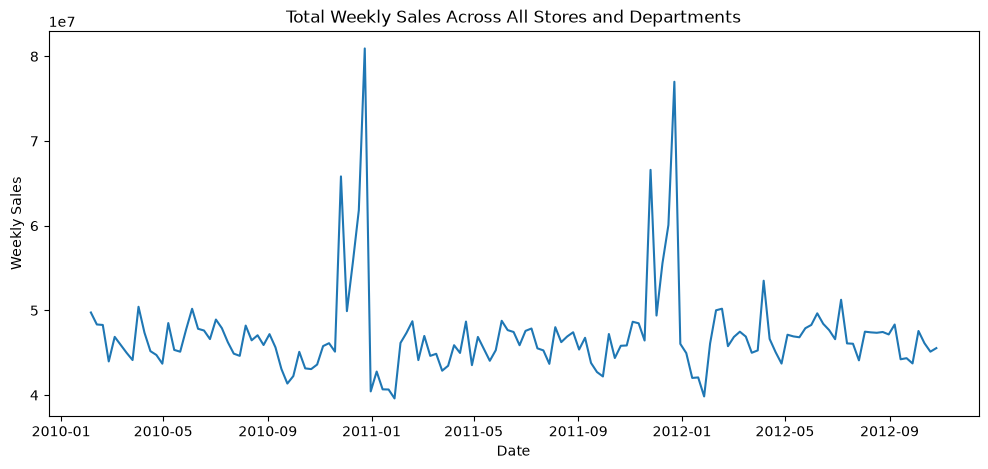

In [36]:
import matplotlib.pyplot as plt

# Aggregating weekly sales across all stores/departments
total_sales = minimal_data.groupby("Date")["Weekly_Sales"].sum().reset_index()

plt.figure(figsize=(12,5))
plt.plot(total_sales['Date'], total_sales['Weekly_Sales'])
plt.title("Total Weekly Sales Across All Stores and Departments")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

As we can see the sales are pretty stable over time. We can see a distinct pattern as well as seasonal spikes at th end of the year, probably corresponding to the Christmas and New Year Holidays.

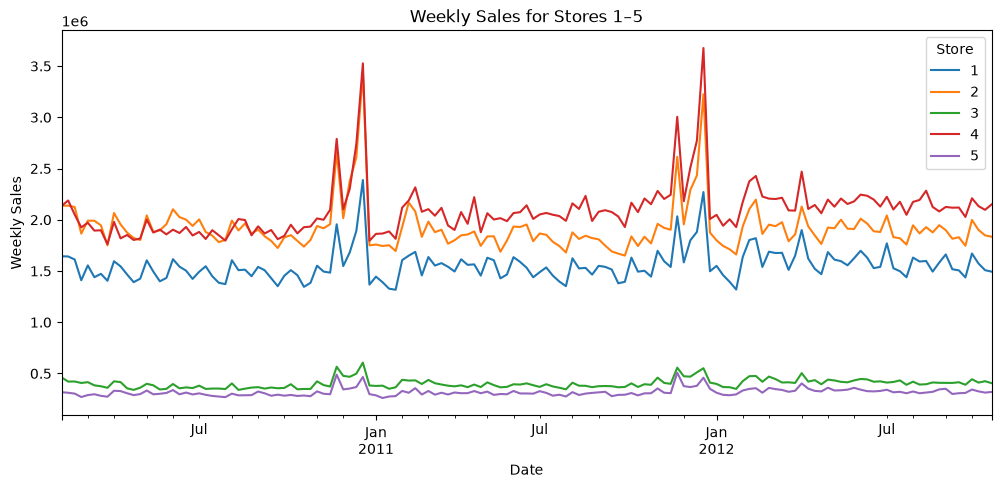

In [37]:
store_sales = minimal_data.groupby(["Date", "Store"])["Weekly_Sales"].sum().unstack()

# Plotting agavage sales on different stores to see if different stores have a different pattern
store_sales.iloc[:, :5].plot(figsize=(12,5))
plt.title("Weekly Sales for Stores 1–5")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

As we can see from the sales of 5 different stores, there is a general pattern, however some stores are very different from one another. For example stores 1,2, and 4 are closer to each other, meaning they have similar avarage sales in comparison to the stores 3 and 5 that have mush less weekly sales. One thing that we can infer from this is that all stores most probably follow the same pattern however they are different in terms of how much oe how little their sales are.

In [38]:
print(store_sales.iloc[:, :3].head())

Store                1           2          3
Date                                         
2010-02-05  1643690.90  2136989.46  461622.22
2010-02-12  1641957.44  2137809.50  420728.96
2010-02-19  1611968.17  2124451.54  421642.19
2010-02-26  1409727.59  1865097.27  407204.86
2010-03-05  1554806.68  1991013.13  415202.04


This is to remember that the weekly sales are for example:

2010-02-05 week, store 1, $1643690.90 sales

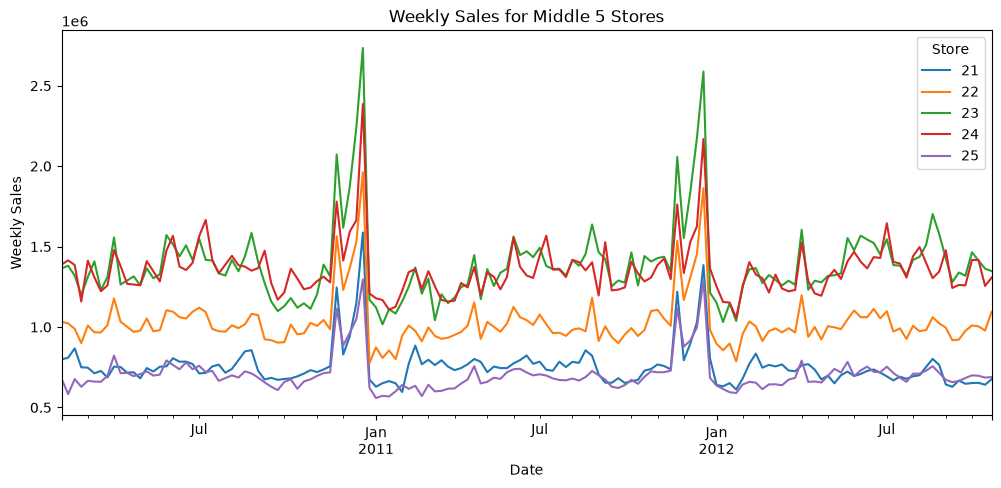

In [39]:
#stores from other 5 stores
n_cols = store_sales.shape[1]
mid = n_cols // 2
store_sales.iloc[:, mid-2:mid+3].plot(figsize=(12,5))
plt.title("Weekly Sales for Middle 5 Stores")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

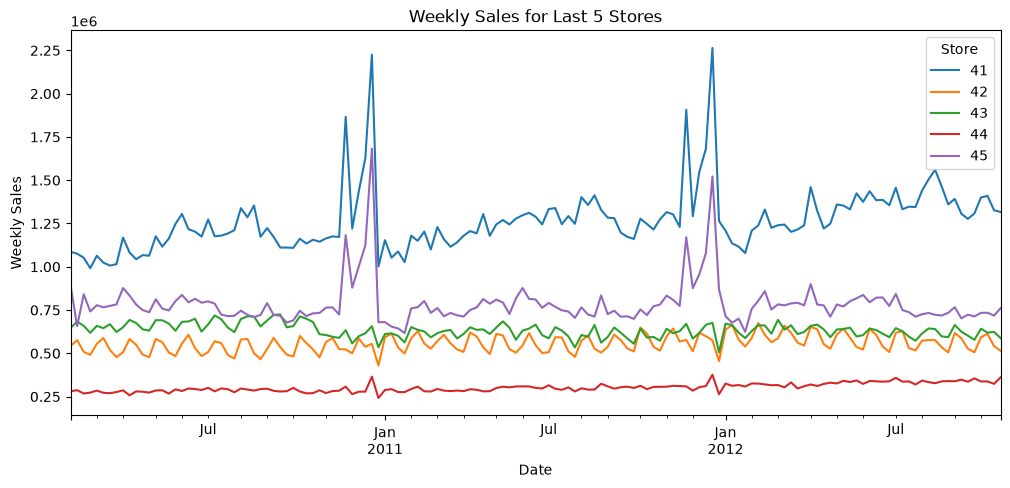

In [40]:
#last 5 stores
store_sales.iloc[:, -5:].plot(figsize=(12,5))
plt.title("Weekly Sales for Last 5 Stores")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

Let's now see if holidays have an impact on sales.

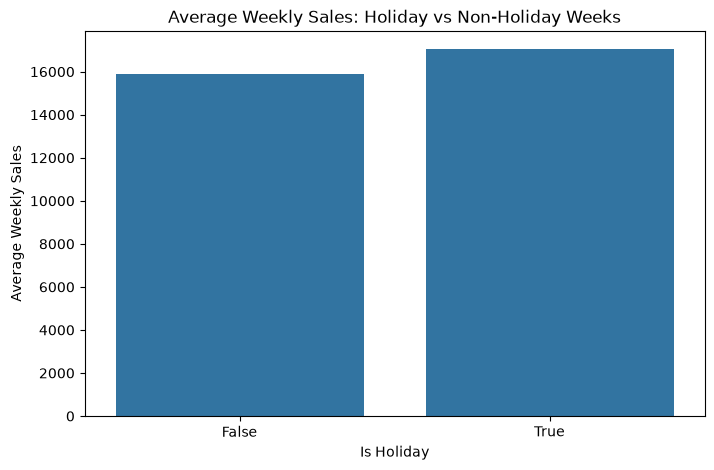

   IsHoliday_x  Weekly_Sales
0        False  15901.445069
1         True  17035.823187


In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

# Mean sales
holiday_mean = minimal_data.groupby("IsHoliday_x")["Weekly_Sales"].mean().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(x="IsHoliday_x", y="Weekly_Sales", data=holiday_mean)

plt.title("Average Weekly Sales: Holiday vs Non-Holiday Weeks")
plt.xlabel("Is Holiday")
plt.ylabel("Average Weekly Sales")
plt.show()

print(holiday_mean)

The analysis shows that holiday weeks are associated with an increase in average weekly sales of approximately 7%. While the effect is positive, it is not as large as expected. This suggests that holiday impact is not uniform across all stores and departments, and that extreme spikes during certain holidays are averaged out when considering the dataset as a whole.

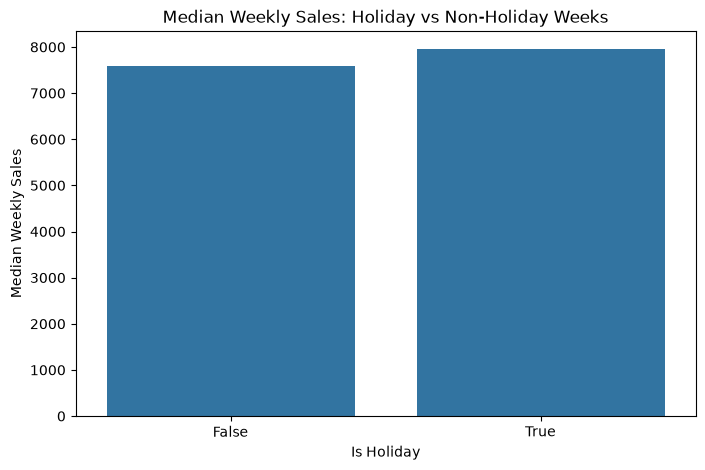

   IsHoliday_x  Weekly_Sales
0        False       7589.95
1         True       7947.74


In [42]:
holiday_median = minimal_data.groupby("IsHoliday_x")["Weekly_Sales"].median().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(x="IsHoliday_x", y="Weekly_Sales", data=holiday_median)

plt.title("Median Weekly Sales: Holiday vs Non-Holiday Weeks")
plt.xlabel("Is Holiday")
plt.ylabel("Median Weekly Sales")
plt.show()

print(holiday_median)

While the average weekly sales increase during holidays is approximately 7%, the median increase is only around 4.7%. This gap between mean and median indicates the presence of outliers, suggesting that holiday effects are driven by a limited number of high-sales events rather than a consistent increase across all observations.

However we need to understand that these are avarage sales across many departments and many stores.

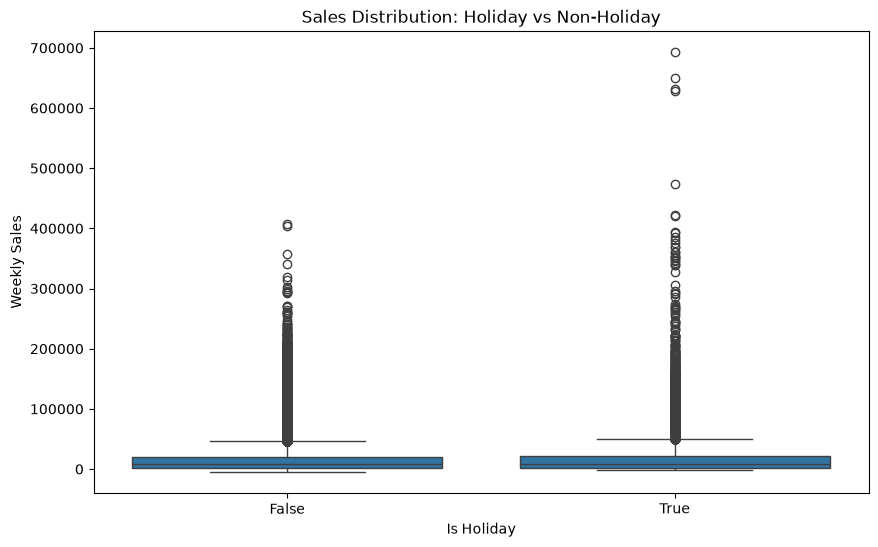

In [43]:
plt.figure(figsize=(10,6))
sns.boxplot(x="IsHoliday_x", y="Weekly_Sales", data=minimal_data)
#plt.yscale("log")
plt.title("Sales Distribution: Holiday vs Non-Holiday")
plt.xlabel("Is Holiday")
plt.ylabel("Weekly Sales")
plt.show()

While median and typical weekly sales show only a modest increase during holiday periods, the distribution reveals significantly more extreme high-value outliers during holidays. This indicates that holiday effects are primarily driven by occasional large sales spikes rather than a consistent increase across all observations.

In [44]:
mean_non_holiday = holiday_mean.loc[holiday_mean["IsHoliday_x"] == False, "Weekly_Sales"].values[0]
mean_holiday = holiday_mean.loc[holiday_mean["IsHoliday_x"] == True, "Weekly_Sales"].values[0]

percent_increase = ((mean_holiday - mean_non_holiday) / mean_non_holiday) * 100

print(f"Percentage change during holidays: {percent_increase:.2f}%")

Percentage change during holidays: 7.13%


In [45]:
# Calculate mean sales per store for holiday vs non-holiday
store_holiday = minimal_data.groupby(["Store", "IsHoliday_x"])["Weekly_Sales"].mean().unstack()

# Rename columns for clarity
store_holiday.columns = ["NonHoliday", "Holiday"]

# Calculate difference
store_holiday["Difference"] = store_holiday["Holiday"] - store_holiday["NonHoliday"]

# Get top and bottom stores
top_stores = store_holiday.sort_values("Difference", ascending=False).head(5)
bottom_stores = store_holiday.sort_values("Difference").head(5)

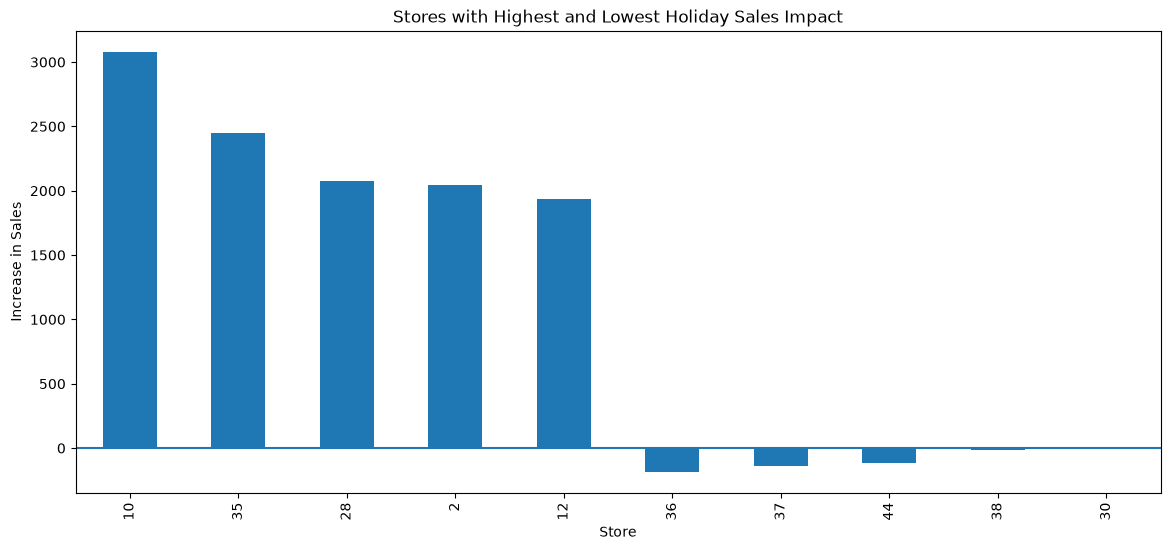

In [46]:
combined = pd.concat([top_stores, bottom_stores])

plt.figure(figsize=(14,6))
combined["Difference"].plot(kind="bar")

plt.title("Stores with Highest and Lowest Holiday Sales Impact")
plt.xlabel("Store")
plt.ylabel("Increase in Sales")
plt.axhline(0)  # important reference line
plt.show()

The impact of holidays is highly heterogeneous across stores. While some stores experience significant increases in sales, others show minimal or even negative changes. This suggests that holiday effects are store-specific and depend on factors such as location, customer base, and product mix.

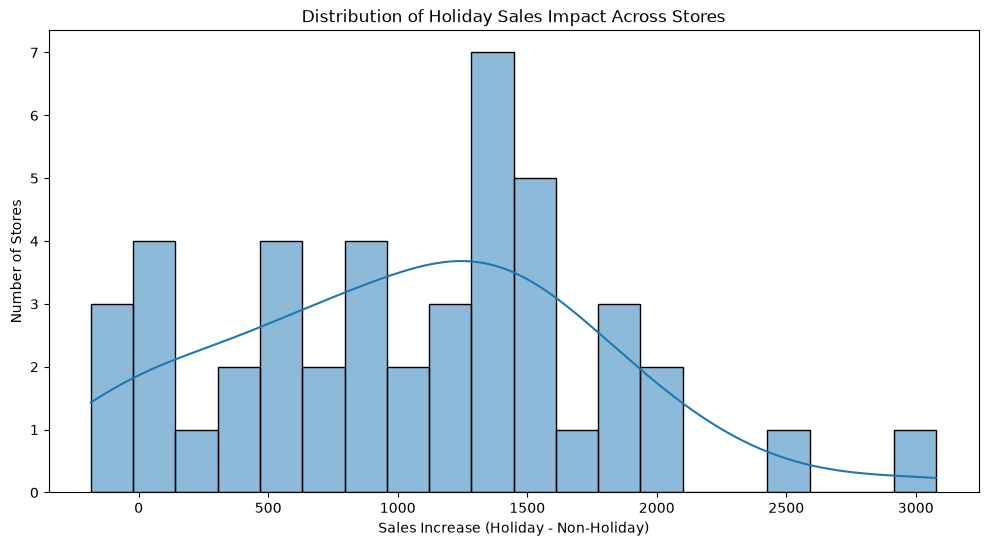

In [47]:
plt.figure(figsize=(12,6))
sns.histplot(store_holiday["Difference"], bins=20, kde=True)

plt.title("Distribution of Holiday Sales Impact Across Stores")
plt.xlabel("Sales Increase (Holiday - Non-Holiday)")
plt.ylabel("Number of Stores")
plt.show()

**Exploratory Data Analysis: Holiday Impact on Weekly Sales**
1. Overall Holiday Effect

Analysis of average weekly sales revealed that holiday weeks have higher sales compared to non-holiday weeks:

Mean sales: ~15,901 → 17,036 (+7% increase)

Median sales: ~7,590 → 7,948 (+4.7% increase)

This indicates that while holidays do boost sales, the increase is moderate rather than dramatic. The gap between mean and median highlights the presence of outliers, suggesting that a small number of extreme high-sales weeks drive much of the effect.

2. Distribution of Sales

The boxplot of weekly sales shows:

Most weeks have similar sales distributions for holiday vs non-holiday periods.

Holidays exhibit more frequent and larger extreme sales spikes (outliers), reaching values much higher than typical weeks.

Interpretation: The holiday effect is not uniform — the majority of sales increase only slightly, while a few weeks experience large surges (e.g., Thanksgiving or Christmas spikes).

3. Store-Level Variation

Analyzing sales at the store level revealed heterogeneous effects:

Top 10 stores: experienced significant holiday-driven increases in sales.

Bottom 10 stores: had minimal or even negative changes during holiday weeks.

This shows that holiday impact is store-specific, likely influenced by factors such as location, customer demographics, and product mix.

Additionally, counting stores by effect:

Many stores see a positive impact, but a substantial number show little or no effect, confirming that the overall average is smoothed by underperforming stores.

4. Key Insights

Holiday weeks increase sales moderately on average, but the effect is highly uneven across stores and weeks.

Extreme spikes during certain holidays drive the mean increase, while the median remains relatively stable.

Store-specific analysis highlights that some locations benefit far more than others, suggesting that a global model may overlook these differences.

For forecasting purposes, including IsHoliday as a feature is useful, but additional store-level modeling or spike-sensitive methods will improve accuracy.

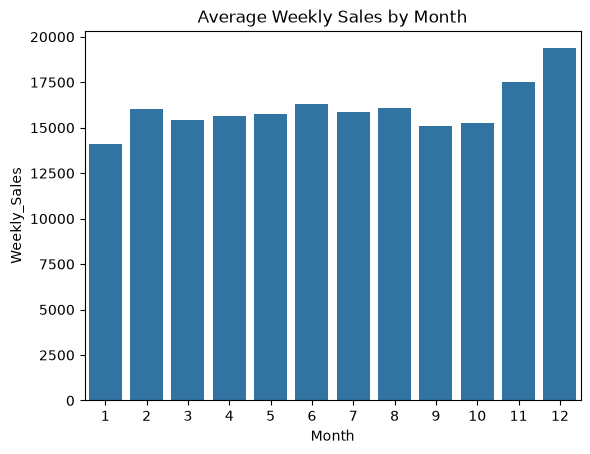

In [48]:
#seasonality by month
minimal_data["Month"] = minimal_data["Date"].dt.month

monthly_sales = minimal_data.groupby("Month")["Weekly_Sales"].mean().reset_index()

sns.barplot(x="Month", y="Weekly_Sales", data=monthly_sales)
plt.title("Average Weekly Sales by Month")
plt.show()

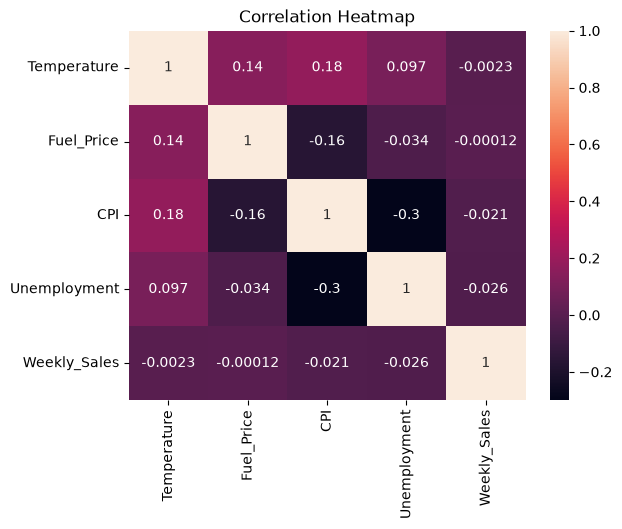

In [49]:
features_of_interest = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

correlations = data[features_of_interest + ["Weekly_Sales"]].corr()
sns.heatmap(correlations, annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [51]:
# Save the processed/cleaned dataset for future phases
minimal_data.to_csv("../data/minimal_features.csv", index=False)